# UCS420 Lab Assignment 7 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [2]:
ROLL_NO = 1024170221       # <-- your full roll number
NAME = "Khushi Agarwal"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [4]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [6]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [7]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170221   Name: Khushi Agarwal   Fingerprint: B12E8F02   Tickets: 13

Ticket_ID                                                                                 Ticket_Text
      T01                                        I can't open the password on my laptop. Please help.
      T02                                Python is running slowly since yesterday. Please resolve it.
      T03 I am unable to use the password when connected to campus Wi-Fi. I have tried several times!
      T04                                                                 The file is 95.5% uploaded.
      T05                                                       The Wi-Fi works, but the VPN doesn't.
      T06                                                     The server failed to open. Please help.
      T07                                      The password has stopped syncing. It worked yesterday.
      T08                                   The server is not working. The same problem occurs aga

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [9]:
# Q1: Preprocessing pipeline

rows = []

for _, row in df.iterrows():
    result = process_ticket(row["Ticket_Text"])
    
    rows.append({
        "Ticket_ID": row["Ticket_ID"],
        "Sentences": len(result["sentences"]),
        "Tokens": len(result["tokens"]),
        "Punctuation": len(result["punct"]),
        "Stopwords": len(result["stops"]),
        "Unique Tokens": len(set(result["tokens"])),
        "Final Tokens": len(result["final"])
    })

q1_table = pd.DataFrame(rows)

# Add TOTAL row for count-based columns
total_row = {
    "Ticket_ID": "TOTAL",
    "Sentences": q1_table["Sentences"].sum(),
    "Tokens": q1_table["Tokens"].sum(),
    "Punctuation": q1_table["Punctuation"].sum(),
    "Stopwords": q1_table["Stopwords"].sum(),
    "Unique Tokens": q1_table["Unique Tokens"].sum(),
    "Final Tokens": q1_table["Final Tokens"].sum()
}

q1_table = pd.concat(
    [q1_table, pd.DataFrame([total_row])],
    ignore_index=True
)

q1_table

,Ticket_ID,Sentences,Tokens,Punctuation,Stopwords,Unique Tokens,Final Tokens
0,T01,2,13,2,4,12,7
1,T02,2,11,2,2,10,7
2,T03,2,19,2,8,17,9
3,T04,1,7,2,2,7,3
4,T05,1,10,2,4,9,4
5,T06,2,9,2,2,8,5
6,T07,2,10,2,3,9,5
7,T08,2,12,2,6,10,4
8,T09,1,7,2,1,7,4
9,T10,2,13,2,4,12,7


In [10]:
# Display detailed preprocessing for one selected ticket

selected_ticket = df.iloc[0]

result = process_ticket(selected_ticket["Ticket_Text"])

print("Selected Ticket:", selected_ticket["Ticket_ID"])
print("\nOriginal Ticket:")
print(selected_ticket["Ticket_Text"])

print("\nTokens:")
print(result["tokens"])

print("\nPunctuation tokens:")
print(result["punct"])

print("\nStopwords:")
print(result["stops"])

print("\nFinal tokens:")
print(result["final"])

Selected Ticket: T01

Original Ticket:
I can't open the password on my laptop. Please help.

Tokens:
['i', 'ca', "n't", 'open', 'the', 'password', 'on', 'my', 'laptop', '.', 'please', 'help', '.']

Punctuation tokens:
['.', '.']

Stopwords:
['i', 'the', 'on', 'my']

Final tokens:
['ca', "n't", 'open', 'password', 'laptop', 'please', 'help']


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* Some final tokens such as n't, 's, and ca are not meaningful standalone words. They come from the way NLTK's word_tokenize() handles contractions. For example, a contraction such as “can't” can be split into ca and n't, while possessive or contracted forms can produce tokens such as 's. These tokens remain in the final token list if they are not removed as punctuation or stopwords.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [13]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# Q2: Regular expressions

import re

# Regex patterns

# 1. Words longer than 5 letters
long_words_pattern = r"\b[A-Za-z]{6,}\b"

# 2. Numbers, decimals and version numbers
# Examples: 95, 95.5, 2.0.1
numbers_pattern = r"\b\d+(?:\.\d+)*\b"

# 3. Capitalized words
capitalized_pattern = r"\b[A-Z][A-Za-z]*\b"

# 4. Words beginning with a vowel
vowel_words_pattern = r"\b[AEIOUaeiou][A-Za-z]*\b"


# Replacement patterns

# Email addresses
email_pattern = r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"

# URLs
url_pattern = r"(?:https?://|www\.)[^\s]+"

# Phone numbers
phone_pattern = r"(?<!\w)(?:\+\d{1,3}[\s-]?)?(?:\d{5}[\s-]\d{5}|\d{3,5}-\d{3,4}-\d{3,4}|\d{10})(?!\w)"


# Function to perform all extractions on a text
def regex_extract(text):
    return {
        "long_words": re.findall(long_words_pattern, text),
        "numbers": re.findall(numbers_pattern, text),
        "capitalized_words": re.findall(capitalized_pattern, text),
        "vowel_words": re.findall(vowel_words_pattern, text)
    }


# Function to perform replacements
def regex_replace(text):
    text = re.sub(email_pattern, "<EMAIL>", text)
    text = re.sub(url_pattern, "<URL>", text)
    text = re.sub(phone_pattern, "<PHONE>", text)
    return text


# Test on TEST_LINES
print("========== TEST_LINES ==========\n")

for i, line in enumerate(TEST_LINES, 1):
    print(f"TEST LINE {i}:")
    print("Original:", line)

    extracted = regex_extract(line)

    print("Words > 5 letters:", extracted["long_words"])
    print("Numbers:", extracted["numbers"])
    print("Capitalized words:", extracted["capitalized_words"])
    print("Vowel-starting words:", extracted["vowel_words"])

    print("After replacement:")
    print(regex_replace(line))
    print("-" * 80)


# Test on all raw tickets
print("\n========== RAW TICKETS ==========\n")

for _, row in df.iterrows():
    text = row["Ticket_Text"]

    print(f"{row['Ticket_ID']}:")
    print("Long words:", regex_extract(text)["long_words"])
    print("Numbers:", regex_extract(text)["numbers"])
    print("Capitalized words:", regex_extract(text)["capitalized_words"])
    print("Vowel-starting words:", regex_extract(text)["vowel_words"])
    print("Replaced:", regex_replace(text))
    print("-" * 80)

========== TEST_LINES ==========

TEST LINE 1:
Original: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Words > 5 letters: ['helpdesk', 'thapar', 'thapar', 'thapar']
Numbers: []
Capitalized words: ['Mail']
Vowel-starting words: ['it', 'edu', 'or', 'a', 'univ', 'ac', 'in', 'edu', 'or', 'edu', 'it']
After replacement:
Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>
--------------------------------------------------------------------------------
TEST LINE 2:
Original: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Words > 5 letters: ['Version']
Numbers: ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.5', '1', '250']
Capitalized words: ['Call', 'Version', 'Rs']
Vowel-starting words: ['or', 'is']
After replacement:
Call <PHONE>, <PHONE> or <PHONE>. Version 2.0.1 is 95.5% done; fee Rs 1,250.
-----------------------------------------------------

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:* 16 of the capitalized words are capitalized only because they occur at the beginning of a sentence. These include words such as Please, The, It, Student, and See. The pronoun I was not counted because it is conventionally capitalized regardless of its position in a sentence.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [35]:
# Your code
# Q3: Custom tokenization

from nltk.tokenize import RegexpTokenizer, word_tokenize

# One pattern that preserves:
# - URLs
# - email addresses
# - phone numbers
# - decimals and versions
# - contractions
# - hyphenated words
# - normal words
# - punctuation

token_pattern = r"""
(?:https?://[^\s]+|www\.[^\s]+)
|
(?:[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,})
|
(?:\+\d{1,3}[\s-]?(?:\d{5}[\s-]\d{5}|\d{3,5}-\d{3,4}-\d{3,4}|\d{10}))
|
(?:\d+(?:\.\d+)*)
|
(?:[A-Za-z]+(?:'[A-Za-z]+))
|
(?:[A-Za-z]+(?:-[A-Za-z]+)+)
|
(?:[A-Za-z]+)
|
(?:[^\w\s])
"""

tokenizer = RegexpTokenizer(token_pattern, flags=re.VERBOSE)


def my_tokenize(text):
    return tokenizer.tokenize(text)


# Test on TEST_LINES
print("========== CUSTOM TOKENIZER: TEST_LINES ==========\n")

for i, line in enumerate(TEST_LINES, 1):
    print(f"TEST LINE {i}:")
    print(my_tokenize(line))
    print()


# Run on all tickets
print("========== CUSTOM TOKENIZER: TICKETS ==========\n")

for _, row in df.iterrows():
    print(row["Ticket_ID"], ":", my_tokenize(row["Ticket_Text"]))

========== CUSTOM TOKENIZER: TEST_LINES ==========

TEST LINE 1:
['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']

TEST LINE 2:
['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175', '-', '239', '-', '3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1', ',', '250', '.']

TEST LINE 3:
['The', 'state-of-the-art', 'lab', "isn't", 'open', ';', 'log-in', 'at', '5.30', 'p', '.', 'm', '.', "didn't", 'work', '.']

========== CUSTOM TOKENIZER: TICKETS ==========

T01 : ['I', "can't", 'open', 'the', 'password', 'on', 'my', 'laptop', '.', 'Please', 'help', '.']
T02 : ['Python', 'is', 'running', 'slowly', 'since', 'yesterday', '.', 'Please', 'resolve', 'it', '.']
T03 : ['I', 'am', 'unable', 'to', 'use', 'the', 'password', 'when', 'connected', 'to', 'campus', 'Wi-Fi', '.', 'I', 'have', 'tried', 'several', 'times', '!']
T04 : ['The', 'file', 'is', '95.5', '%', 'uploaded',

In [37]:
# Compare custom tokenizer with word_tokenize()

print("========== COMPARISON ==========\n")

for i, line in enumerate(TEST_LINES, 1):
    custom = my_tokenize(line)
    nltk_tokens = word_tokenize(line)

    print(f"TEST LINE {i}")
    print("Custom tokenizer:")
    print(custom)

    print("\nword_tokenize():")
    print(nltk_tokens)

    print("\n" + "-" * 80 + "\n")

========== COMPARISON ==========

TEST LINE 1
Custom tokenizer:
['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']

word_tokenize():
['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

--------------------------------------------------------------------------------

TEST LINE 2
Custom tokenizer:
['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175', '-', '239', '-', '3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1', ',', '250', '.']

word_tokenize():
['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

--------------------------------------------------------------------------------

TEST LINE 3
Custom tokenizer:
['The', 'state-of-th

**Observe:** Identify at least three differences and explain them

*Your answer:* The custom tokenizer keeps contractions such as isn't as one token, whereas word_tokenize() can split them into is and n't.

The custom tokenizer keeps hyphenated expressions such as Wi-Fi and state-of-the-art as one token, whereas word_tokenize() generally separates the hyphenated components.

The custom tokenizer keeps decimals and versions such as 95.5 and 2.0.1 as single tokens, whereas a general word tokenizer may split these around punctuation.

The custom tokenizer is specifically designed to preserve email addresses, URLs, and phone numbers as single tokens, while word_tokenize() may divide these into multiple tokens.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [40]:
# Your code
# Q4: Stemming and Lemmatization

from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk.corpus import wordnet
import pandas as pd
import nltk

# Create stemmers and lemmatizer
porter = PorterStemmer()
lancaster = LancasterStemmer()

# We choose "ing" because our dataset contains words such as
# running, working, syncing, responding, etc.
regexp = RegexpStemmer(r"ing$", min=3)

lemmatizer = WordNetLemmatizer()


# Convert POS tag from nltk.pos_tag() to WordNet POS
def get_wordnet_pos(tag):
    if tag.startswith("J"):
        return wordnet.ADJ
    elif tag.startswith("V"):
        return wordnet.VERB
    elif tag.startswith("N"):
        return wordnet.NOUN
    elif tag.startswith("R"):
        return wordnet.ADV
    else:
        return wordnet.NOUN


# Get unique final tokens from all tickets
all_final_tokens = []

for _, row in df.iterrows():
    result = process_ticket(row["Ticket_Text"])
    all_final_tokens.extend(result["final"])

unique_final_tokens = sorted(set(all_final_tokens))


# POS tagging
pos_tags = nltk.pos_tag(unique_final_tokens)


# Compare all four methods
q4_rows = []

for word, tag in pos_tags:

    wordnet_pos = get_wordnet_pos(tag)

    porter_result = porter.stem(word)
    lancaster_result = lancaster.stem(word)
    regexp_result = regexp.stem(word)
    lemma_result = lemmatizer.lemmatize(word, pos=wordnet_pos)

    # Only keep words where at least two methods give different results
    if len(set([
        porter_result,
        lancaster_result,
        regexp_result,
        lemma_result
    ])) > 1:

        q4_rows.append({
            "Word": word,
            "POS": tag,
            "Porter": porter_result,
            "Lancaster": lancaster_result,
            "Regexp": regexp_result,
            "WordNet": lemma_result
        })


q4_table = pd.DataFrame(q4_rows)

q4_table

,Word,POS,Porter,Lancaster,Regexp,WordNet
0,assignment,NN,assign,assign,assignment,assignment
1,campus,VB,campu,camp,campus,campus
2,connected,JJ,connect,connect,connected,connected
3,deadline,NN,deadlin,deadlin,deadline,deadline
4,details,NNS,detail,detail,details,detail
5,failed,VBD,fail,fail,failed,fail
6,file,NN,file,fil,file,file
7,https,JJ,http,https,https,https
8,lms,NNS,lm,lms,lms,lm
9,mobile,VBP,mobil,mobl,mobile,mobile


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:* Over-stemming: running is stemmed to runn by Porter and Regexp, which is not a meaningful English word.
Under-stemming: connected remains connected with WordNet instead of reducing to the base form connect.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

========== CORPUS STATISTICS ==========


,Corpus,Total Tokens,Unique Tokens,TTR
0,S1,143,74,0.517483
1,S2,117,68,0.581197
2,S3,73,50,0.684932
3,S4,73,48,0.657534



========== TOP 10 WORDS: S1 ==========
[('.', 20), ('the', 12), ('i', 5), ('please', 4), ('is', 4), ('to', 4), ('open', 3), ('password', 3), ('help', 3), ('yesterday', 3)]

========== TOP 10 WORDS: S3 ==========
[('please', 4), ('open', 3), ('password', 3), ('help', 3), ('yesterday', 3), ("n't", 2), ('use', 2), ('wi-fi', 2), ('tried', 2), ('several', 2)]


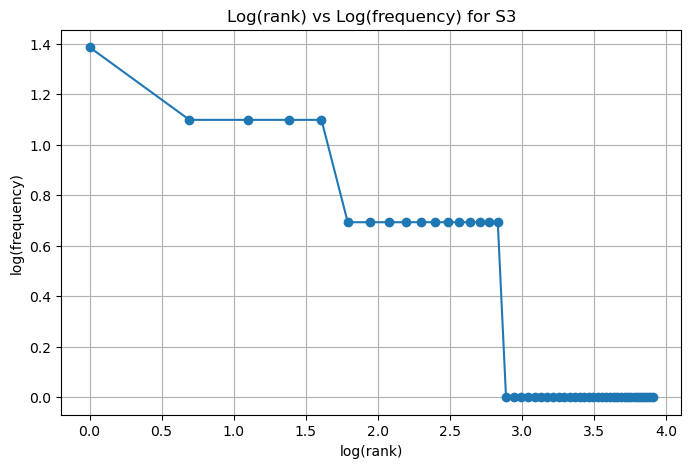


========== TOP 5 BIGRAMS: S1 ==========
[(('.', 'the'), 7), (('.', 'please'), 4), (('the', 'password'), 3), (('please', 'help'), 3), (('help', '.'), 3)]

========== TOP 5 BIGRAMS: S3 ==========
[(('please', 'help'), 3), (('tried', 'several'), 2), (('several', 'times'), 2), (('failed', 'open'), 2), (('worked', 'yesterday'), 2)]


In [43]:
# Your code

from collections import Counter
import math
import matplotlib.pyplot as plt

# Create the four corpora
S1 = []   # All tokens
S2 = []   # Tokens without punctuation
S3 = []   # Final tokens
S4 = []   # S3 after Porter stemming


# Build S1, S2 and S3 from every ticket
for _, row in df.iterrows():

    result = process_ticket(row["Ticket_Text"])

    # S1: all tokens
    S1.extend(result["tokens"])

    # S2: tokens without punctuation
    S2.extend([
        token for token in result["tokens"]
        if token not in result["punct"]
    ])

    # S3: final tokens
    S3.extend(result["final"])


# S4: Porter-stemmed version of S3
S4 = [porter.stem(token) for token in S3]


# Function to calculate statistics
def corpus_stats(tokens):
    total = len(tokens)
    unique = len(set(tokens))
    ttr = unique / total if total > 0 else 0

    return total, unique, ttr


# Calculate statistics for all four corpora
stats = []

for name, corpus in [("S1", S1), ("S2", S2), ("S3", S3), ("S4", S4)]:
    total, unique, ttr = corpus_stats(corpus)

    stats.append({
        "Corpus": name,
        "Total Tokens": total,
        "Unique Tokens": unique,
        "TTR": ttr
    })


stats_df = pd.DataFrame(stats)

print("========== CORPUS STATISTICS ==========")
display(stats_df)


# --------------------------------------------------
# TOP 10 WORDS OF S1 AND S3
# --------------------------------------------------

print("\n========== TOP 10 WORDS: S1 ==========")

S1_counter = Counter(S1)

print(S1_counter.most_common(10))


print("\n========== TOP 10 WORDS: S3 ==========")

S3_counter = Counter(S3)

print(S3_counter.most_common(10))


# --------------------------------------------------
# LOG(RANK) vs LOG(FREQUENCY) PLOT FOR S3
# --------------------------------------------------

frequencies = sorted(S3_counter.values(), reverse=True)

ranks = list(range(1, len(frequencies) + 1))

log_ranks = [math.log(r) for r in ranks]
log_frequencies = [math.log(f) for f in frequencies]


plt.figure(figsize=(8, 5))

plt.plot(log_ranks, log_frequencies, marker="o")

plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.title("Log(rank) vs Log(frequency) for S3")

plt.grid(True)
plt.show()


# --------------------------------------------------
# TOP 5 BIGRAMS OF S1 AND S3
# --------------------------------------------------

def get_bigrams(tokens):
    return list(zip(tokens[:-1], tokens[1:]))


S1_bigrams = Counter(get_bigrams(S1))
S3_bigrams = Counter(get_bigrams(S3))


print("\n========== TOP 5 BIGRAMS: S1 ==========")
print(S1_bigrams.most_common(5))


print("\n========== TOP 5 BIGRAMS: S3 ==========")
print(S3_bigrams.most_common(5))

## 6. Interpretation
Answer briefly:
(a) Why does TTR change from S1 to S4 in your dataset?
(b) Give one example where word_tokenize() and your tokenizer differ. Explain the difference. (c) Give one example where stemming produces an undesirable result.
(d) Give one example where POS-aware lemmatization preserves meaning better than stemming.

(a) TTR increases from S1 to S3 because preprocessing removes punctuation, stopwords, and other unwanted tokens, reducing the total number of tokens. TTR rises from 0.517 in S1 to 0.685 in S3. After Porter stemming, some words are merged into the same stem, reducing unique tokens from 50 to 48, so TTR slightly decreases to 0.658 in S4.

(b) For example, the custom tokenizer keeps a contraction such as isn't as one token, whereas word_tokenize() splits it into is and n't. The custom tokenizer was specifically designed to preserve contractions as single tokens.

(c) An undesirable stemming result is running → runn with Porter stemming. runn is not a meaningful English word, showing that stemming can sometimes remove too much or produce an invalid stem.

(d) For connected, POS-aware WordNet lemmatization gives connected because the word is tagged as an adjective (JJ), while stemming reduces it to connect. Thus, POS-aware lemmatization preserves the word's grammatical role and meaning more accurately.